# Introduction to Machine Learning with PyTorch
## Project: Finding Donors for *CharityML*

Welcome to the first project of the Data Scientist Nanodegree! In this notebook, some template code has already been provided for you, and it will be your job to implement the additional functionality necessary to successfully complete this project. Sections that begin with **'Implementation'** in the header indicate that the following block of code will require additional functionality which you must provide. Instructions will be provided for each section and the specifics of the implementation are marked in the code block with a `'TODO'` statement. Please be sure to read the instructions carefully!

In addition to implementing code, there will be questions that you must answer which relate to the project and your implementation. Each section where you will answer a question is preceded by a **'Question X'** header. Carefully read each question and provide thorough answers in the following text boxes that begin with **'Answer:'**. Your project submission will be evaluated based on your answers to each of the questions and the implementation you provide.  

>**Note:** Please specify WHICH VERSION OF PYTHON you are using when submitting this notebook. Code and Markdown cells can be executed using the **Shift + Enter** keyboard shortcut. In addition, Markdown cells can be edited by typically double-clicking the cell to enter edit mode.

**Python version used for this submission:** Python 3.10 (3.10.11), with numpy 1.26.3, pandas 2.1.4, scikit-learn 1.4.0, matplotlib 3.8.2 and seaborn 0.13.2. The first code cell prints the exact versions.

## Getting Started

In this project, you will employ several supervised algorithms of your choice to accurately model individuals' income using data collected from the 1994 U.S. Census. You will then choose the best candidate algorithm from preliminary results and further optimize this algorithm to best model the data. Your goal with this implementation is to construct a model that accurately predicts whether an individual makes more than $50,000. This sort of task can arise in a non-profit setting, where organizations survive on donations.  Understanding an individual's income can help a non-profit better understand how large of a donation to request, or whether or not they should reach out to begin with.  While it can be difficult to determine an individual's general income bracket directly from public sources, we can (as we will see) infer this value from other publically available features. 

The dataset for this project originates from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/datasets/Census+Income). The datset was donated by Ron Kohavi and Barry Becker, after being published in the article _"Scaling Up the Accuracy of Naive-Bayes Classifiers: A Decision-Tree Hybrid"_. You can find the article by Ron Kohavi [online](https://www.aaai.org/Papers/KDD/1996/KDD96-033.pdf). The data we investigate here consists of small changes to the original dataset, such as removing the `'fnlwgt'` feature and records with missing or ill-formatted entries.

----
## Exploring the Data
Run the code cell below to load necessary Python libraries and load the census data. Note that the last column from this dataset, `'income'`, will be our target label (whether an individual makes more than, or at most, $50,000 annually). All other columns are features about each individual in the census database.

In [1]:
# Import libraries necessary for this project
import numpy as np
import pandas as pd
from time import time
from IPython.display import display # Allows the use of display() for DataFrames

# Import supplementary visualization code visuals.py
import visuals as vs

# Hide the harmless 'FigureCanvasAgg is non-interactive' warning raised by fig.show() in visuals.py
import warnings
warnings.filterwarnings("ignore", message="FigureCanvasAgg is non-interactive")

# Pretty display for notebooks
%matplotlib inline

# Report the Python and library versions used for this submission
import sys, sklearn, matplotlib
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

# Load the Census dataset
data = pd.read_csv("census.csv")

# Success - Display the first record
display(data.head(n=1))

Python 3.10.11 | numpy 1.26.3 | pandas 2.1.4 | scikit-learn 1.4.0 | matplotlib 3.8.2


,age,workclass,education_level,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,2174.0,0.0,40.0,United-States,<=50K


### Implementation: Data Exploration
A cursory investigation of the dataset will determine how many individuals fit into either group, and will tell us about the percentage of these individuals making more than \$50,000. In the code cell below, you will need to compute the following:
- The total number of records, `'n_records'`
- The number of individuals making more than \$50,000 annually, `'n_greater_50k'`.
- The number of individuals making at most \$50,000 annually, `'n_at_most_50k'`.
- The percentage of individuals making more than \$50,000 annually, `'greater_percent'`.

**HINT:** You may need to look at the table above to understand how the `'income'` entries are formatted. 

In [2]:
# TODO: Total number of records
n_records = data.shape[0]

# TODO: Number of records where individual's income is more than $50,000
n_greater_50k = (data['income'] == '>50K').sum()

# TODO: Number of records where individual's income is at most $50,000
n_at_most_50k = (data['income'] == '<=50K').sum()

# TODO: Percentage of individuals whose income is more than $50,000
greater_percent = 100.0 * n_greater_50k / n_records

# Print the results
print("Total number of records: {}".format(n_records))
print("Individuals making more than $50,000: {}".format(n_greater_50k))
print("Individuals making at most $50,000: {}".format(n_at_most_50k))
print("Percentage of individuals making more than $50,000: {:.2f}%".format(greater_percent))

Total number of records: 45222
Individuals making more than $50,000: 11208
Individuals making at most $50,000: 34014
Percentage of individuals making more than $50,000: 24.78%


**Featureset Exploration**

* **age**: continuous. 
* **workclass**: Private, Self-emp-not-inc, Self-emp-inc, Federal-gov, Local-gov, State-gov, Without-pay, Never-worked. 
* **education**: Bachelors, Some-college, 11th, HS-grad, Prof-school, Assoc-acdm, Assoc-voc, 9th, 7th-8th, 12th, Masters, 1st-4th, 10th, Doctorate, 5th-6th, Preschool. 
* **education-num**: continuous. 
* **marital-status**: Married-civ-spouse, Divorced, Never-married, Separated, Widowed, Married-spouse-absent, Married-AF-spouse. 
* **occupation**: Tech-support, Craft-repair, Other-service, Sales, Exec-managerial, Prof-specialty, Handlers-cleaners, Machine-op-inspct, Adm-clerical, Farming-fishing, Transport-moving, Priv-house-serv, Protective-serv, Armed-Forces. 
* **relationship**: Wife, Own-child, Husband, Not-in-family, Other-relative, Unmarried. 
* **race**: Black, White, Asian-Pac-Islander, Amer-Indian-Eskimo, Other. 
* **sex**: Female, Male. 
* **capital-gain**: continuous. 
* **capital-loss**: continuous. 
* **hours-per-week**: continuous. 
* **native-country**: United-States, Cambodia, England, Puerto-Rico, Canada, Germany, Outlying-US(Guam-USVI-etc), India, Japan, Greece, South, China, Cuba, Iran, Honduras, Philippines, Italy, Poland, Jamaica, Vietnam, Mexico, Portugal, Ireland, France, Dominican-Republic, Laos, Ecuador, Taiwan, Haiti, Columbia, Hungary, Guatemala, Nicaragua, Scotland, Thailand, Yugoslavia, El-Salvador, Trinadad&Tobago, Peru, Hong, Holand-Netherlands.

----
## Preparing the Data
Before data can be used as input for machine learning algorithms, it often must be cleaned, formatted, and restructured — this is typically known as **preprocessing**. Fortunately, for this dataset, there are no invalid or missing entries we must deal with, however, there are some qualities about certain features that must be adjusted. This preprocessing can help tremendously with the outcome and predictive power of nearly all learning algorithms.

### Transforming Skewed Continuous Features
A dataset may sometimes contain at least one feature whose values tend to lie near a single number, but will also have a non-trivial number of vastly larger or smaller values than that single number.  Algorithms can be sensitive to such distributions of values and can underperform if the range is not properly normalized. With the census dataset two features fit this description: '`capital-gain'` and `'capital-loss'`. 

Run the code cell below to plot a histogram of these two features. Note the range of the values present and how they are distributed.

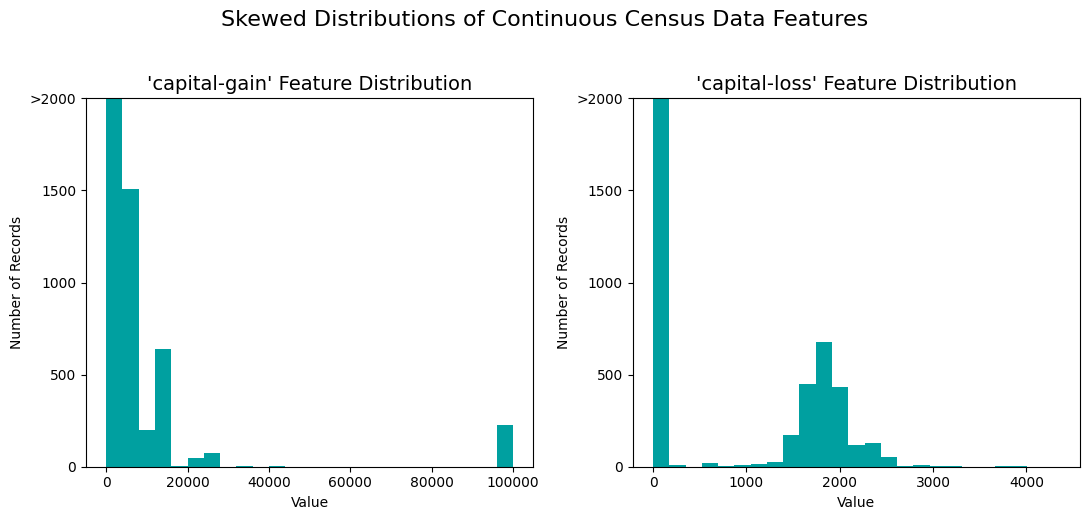

In [3]:
# Split the data into features and target label
income_raw = data['income']
features_raw = data.drop('income', axis = 1)

# Visualize skewed continuous features of original data
vs.distribution(data)

For highly-skewed feature distributions such as `'capital-gain'` and `'capital-loss'`, it is common practice to apply a <a href="https://en.wikipedia.org/wiki/Data_transformation_(statistics)">logarithmic transformation</a> on the data so that the very large and very small values do not negatively affect the performance of a learning algorithm. Using a logarithmic transformation significantly reduces the range of values caused by outliers. Care must be taken when applying this transformation however: The logarithm of `0` is undefined, so we must translate the values by a small amount above `0` to apply the the logarithm successfully.

Run the code cell below to perform a transformation on the data and visualize the results. Again, note the range of values and how they are distributed. 

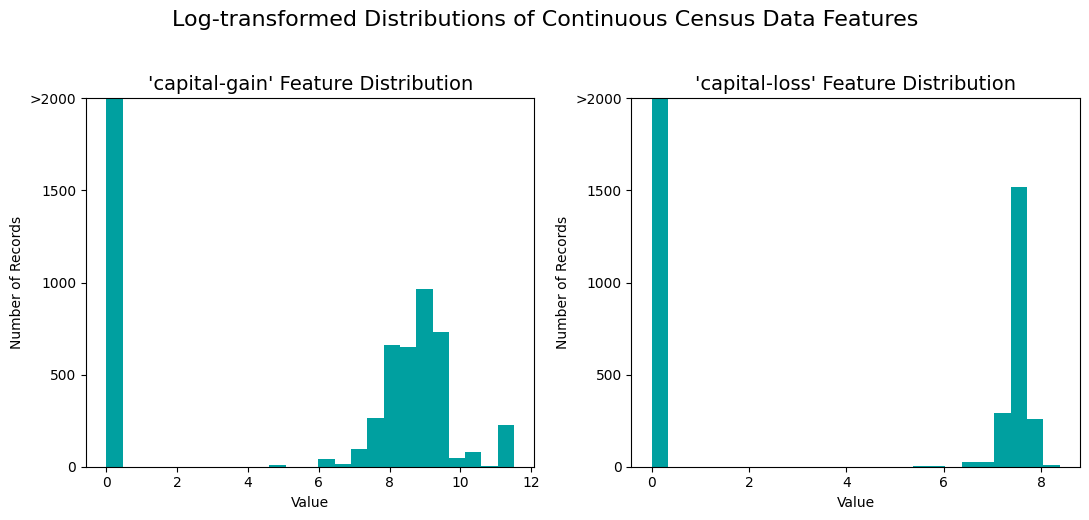

In [4]:
# Log-transform the skewed features
skewed = ['capital-gain', 'capital-loss']
features_log_transformed = pd.DataFrame(data = features_raw)
features_log_transformed[skewed] = features_raw[skewed].apply(lambda x: np.log(x + 1))

# Visualize the new log distributions
vs.distribution(features_log_transformed, transformed = True)

### Normalizing Numerical Features
In addition to performing transformations on features that are highly skewed, it is often good practice to perform some type of scaling on numerical features. Applying a scaling to the data does not change the shape of each feature's distribution (such as `'capital-gain'` or `'capital-loss'` above); however, normalization ensures that each feature is treated equally when applying supervised learners. Note that once scaling is applied, observing the data in its raw form will no longer have the same original meaning, as exampled below.

Run the code cell below to normalize each numerical feature. We will use [`sklearn.preprocessing.MinMaxScaler`](http://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html) for this.

In [5]:
# Import sklearn.preprocessing.StandardScaler
from sklearn.preprocessing import MinMaxScaler

# Initialize a scaler, then apply it to the features
scaler = MinMaxScaler() # default=(0, 1)
numerical = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

features_log_minmax_transform = pd.DataFrame(data = features_log_transformed)
features_log_minmax_transform[numerical] = scaler.fit_transform(features_log_transformed[numerical])

# Show an example of a record with scaling applied
display(features_log_minmax_transform.head(n = 5))

,age,workclass,education_level,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,0.301370,State-gov,Bachelors,0.800000,Never-married,Adm-clerical,Not-in-family,White,Male,0.667492,0.0,0.397959,United-States
1,0.452055,Self-emp-not-inc,Bachelors,0.800000,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.000000,0.0,0.122449,United-States
2,0.287671,Private,HS-grad,0.533333,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.000000,0.0,0.397959,United-States
3,0.493151,Private,11th,0.400000,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.000000,0.0,0.397959,United-States
4,0.150685,Private,Bachelors,0.800000,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.000000,0.0,0.397959,Cuba


### Implementation: Data Preprocessing

From the table in **Exploring the Data** above, we can see there are several features for each record that are non-numeric. Typically, learning algorithms expect input to be numeric, which requires that non-numeric features (called *categorical variables*) be converted. One popular way to convert categorical variables is by using the **one-hot encoding** scheme. One-hot encoding creates a _"dummy"_ variable for each possible category of each non-numeric feature. For example, assume `someFeature` has three possible entries: `A`, `B`, or `C`:

|   | someFeature |                    
| :-: | :-: |                            
| 0 |  B  |  
| 1 |  C  |
| 2 |  A  |  

We then encode this feature into `someFeature_A`, `someFeature_B` and `someFeature_C`:

|| someFeature_A | someFeature_B | someFeature_C |
| :-: | :-: | :-: | :-: |
|0| 0 | 1 | 0 |
|1| 0 | 0 | 1 |
|2| 1 | 0 | 0 |

Additionally, as with the non-numeric features, we need to convert the non-numeric target label, `'income'` to numerical values for the learning algorithm to work. Since there are only two possible categories for this label ("<=50K" and ">50K"), we can avoid using one-hot encoding and simply encode these two categories as `0` and `1`, respectively. In code cell below, you will need to implement the following:
 - Use [`pandas.get_dummies()`](http://pandas.pydata.org/pandas-docs/stable/generated/pandas.get_dummies.html?highlight=get_dummies#pandas.get_dummies) to perform one-hot encoding on the `'features_log_minmax_transform'` data.
 - Convert the target label `'income_raw'` to numerical entries.
   - Set records with "<=50K" to `0` and records with ">50K" to `1`.

In [6]:
# TODO: One-hot encode the 'features_log_minmax_transform' data using pandas.get_dummies()
features_final = pd.get_dummies(features_log_minmax_transform)

# TODO: Encode the 'income_raw' data to numerical values
income = income_raw.map({'<=50K': 0, '>50K': 1})

# Print the number of features after one-hot encoding
encoded = list(features_final.columns)
print("{} total features after one-hot encoding.".format(len(encoded)))

# Uncomment the following line to see the encoded feature names
print(encoded)

103 total features after one-hot encoding.
['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week', 'workclass_ Federal-gov', 'workclass_ Local-gov', 'workclass_ Private', 'workclass_ Self-emp-inc', 'workclass_ Self-emp-not-inc', 'workclass_ State-gov', 'workclass_ Without-pay', 'education_level_ 10th', 'education_level_ 11th', 'education_level_ 12th', 'education_level_ 1st-4th', 'education_level_ 5th-6th', 'education_level_ 7th-8th', 'education_level_ 9th', 'education_level_ Assoc-acdm', 'education_level_ Assoc-voc', 'education_level_ Bachelors', 'education_level_ Doctorate', 'education_level_ HS-grad', 'education_level_ Masters', 'education_level_ Preschool', 'education_level_ Prof-school', 'education_level_ Some-college', 'marital-status_ Divorced', 'marital-status_ Married-AF-spouse', 'marital-status_ Married-civ-spouse', 'marital-status_ Married-spouse-absent', 'marital-status_ Never-married', 'marital-status_ Separated', 'marital-status_ Widowed', 'occupation_ A

### Shuffle and Split Data
Now all _categorical variables_ have been converted into numerical features, and all numerical features have been normalized. As always, we will now split the data (both features and their labels) into training and test sets. 80% of the data will be used for training and 20% for testing.

Run the code cell below to perform this split.

In [7]:
# Import train_test_split
from sklearn.model_selection import train_test_split

# Split the 'features' and 'income' data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(features_final, 
                                                    income, 
                                                    test_size = 0.2, 
                                                    random_state = 0)

# Show the results of the split
print("Training set has {} samples.".format(X_train.shape[0]))
print("Testing set has {} samples.".format(X_test.shape[0]))

Training set has 36177 samples.
Testing set has 9045 samples.


----
## Evaluating Model Performance
In this section, we will investigate four different algorithms, and determine which is best at modeling the data. Three of these algorithms will be supervised learners of your choice, and the fourth algorithm is known as a *naive predictor*.

### Metrics and the Naive Predictor
*CharityML*, equipped with their research, knows individuals that make more than \$50,000 are most likely to donate to their charity. Because of this, *CharityML* is particularly interested in predicting who makes more than \$50,000 accurately. It would seem that using **accuracy** as a metric for evaluating a particular model's performace would be appropriate. Additionally, identifying someone that *does not* make more than \$50,000 as someone who does would be detrimental to *CharityML*, since they are looking to find individuals willing to donate. Therefore, a model's ability to precisely predict those that make more than \$50,000 is *more important* than the model's ability to **recall** those individuals. We can use **F-beta score** as a metric that considers both precision and recall:

$$ F_{\beta} = (1 + \beta^2) \cdot \frac{precision \cdot recall}{\left( \beta^2 \cdot precision \right) + recall} $$

In particular, when $\beta = 0.5$, more emphasis is placed on precision. This is called the **F$_{0.5}$ score** (or F-score for simplicity).

Looking at the distribution of classes (those who make at most \$50,000, and those who make more), it's clear most individuals do not make more than \$50,000. This can greatly affect **accuracy**, since we could simply say *"this person does not make more than \$50,000"* and generally be right, without ever looking at the data! Making such a statement would be called **naive**, since we have not considered any information to substantiate the claim. It is always important to consider the *naive prediction* for your data, to help establish a benchmark for whether a model is performing well. That been said, using that prediction would be pointless: If we predicted all people made less than \$50,000, *CharityML* would identify no one as donors. 


#### Note: Recap of accuracy, precision, recall

**Accuracy** measures how often the classifier makes the correct prediction. It’s the ratio of the number of correct predictions to the total number of predictions (the number of test data points).

**Precision** tells us what proportion of messages we classified as spam, actually were spam.
It is a ratio of true positives(words classified as spam, and which are actually spam) to all positives(all words classified as spam, irrespective of whether that was the correct classificatio), in other words it is the ratio of

`[True Positives/(True Positives + False Positives)]`

**Recall(sensitivity)** tells us what proportion of messages that actually were spam were classified by us as spam.
It is a ratio of true positives(words classified as spam, and which are actually spam) to all the words that were actually spam, in other words it is the ratio of

`[True Positives/(True Positives + False Negatives)]`

For classification problems that are skewed in their classification distributions like in our case, for example if we had a 100 text messages and only 2 were spam and the rest 98 weren't, accuracy by itself is not a very good metric. We could classify 90 messages as not spam(including the 2 that were spam but we classify them as not spam, hence they would be false negatives) and 10 as spam(all 10 false positives) and still get a reasonably good accuracy score. For such cases, precision and recall come in very handy. These two metrics can be combined to get the F1 score, which is weighted average(harmonic mean) of the precision and recall scores. This score can range from 0 to 1, with 1 being the best possible F1 score(we take the harmonic mean as we are dealing with ratios).

### Question 1 - Naive Predictor Performace
* If we chose a model that always predicted an individual made more than $50,000, what would  that model's accuracy and F-score be on this dataset? You must use the code cell below and assign your results to `'accuracy'` and `'fscore'` to be used later.

**Please note** that the the purpose of generating a naive predictor is simply to show what a base model without any intelligence would look like. In the real world, ideally your base model would be either the results of a previous model or could be based on a research paper upon which you are looking to improve. When there is no benchmark model set, getting a result better than random choice is a place you could start from.

**HINT:** 

* When we have a model that always predicts '1' (i.e. the individual makes more than 50k) then our model will have no True Negatives(TN) or False Negatives(FN) as we are not making any negative('0' value) predictions. Therefore our Accuracy in this case becomes the same as our Precision (True Positives / (True Positives + False Positives)) as every prediction that we have made with value '1' that should have '0' becomes a False Positive; therefore our denominator in this case is the total number of records we have in total. 
* Our Recall score (True Positives / (True Positives + False Negatives)) in this setting becomes 1 as we have no False Negatives.

In [8]:
TP = np.sum(income) # Counting the ones as this is the naive case. Note that 'income' is the 'income_raw' data encoded to numerical values done in the data preprocessing step.
FP = income.count() - TP # Specific to the naive case

TN = 0 # No predicted negatives in the naive case
FN = 0 # No predicted negatives in the naive case

# TODO: Calculate accuracy, precision and recall
accuracy = (TP + TN) / (TP + FP + TN + FN)
recall = TP / (TP + FN)
precision = TP / (TP + FP)

# TODO: Calculate F-score using the formula above for beta = 0.5 and correct values for precision and recall.
beta = 0.5
fscore = (1 + beta**2) * (precision * recall) / ((beta**2 * precision) + recall)

# Print the results
print("TP: {}, FP: {}, TN: {}, FN: {}".format(TP, FP, TN, FN))
print("Precision: {:.4f}, Recall: {:.4f}".format(precision, recall))
print("Naive Predictor: [Accuracy score: {:.4f}, F-score: {:.4f}]".format(accuracy, fscore))

TP: 11208, FP: 34014, TN: 0, FN: 0
Precision: 0.2478, Recall: 1.0000
Naive Predictor: [Accuracy score: 0.2478, F-score: 0.2917]


###  Supervised Learning Models
**The following are some of the supervised learning models that are currently available in** [`scikit-learn`](http://scikit-learn.org/stable/supervised_learning.html) **that you may choose from:**
- Gaussian Naive Bayes (GaussianNB)
- Decision Trees
- Ensemble Methods (Bagging, AdaBoost, Random Forest, Gradient Boosting)
- K-Nearest Neighbors (KNeighbors)
- Stochastic Gradient Descent Classifier (SGDC)
- Support Vector Machines (SVM)
- Logistic Regression

### Question 2 - Model Application
List three of the supervised learning models above that are appropriate for this problem that you will test on the census data. For each model chosen

- Describe one real-world application in industry where the model can be applied. 
- What are the strengths of the model; when does it perform well?
- What are the weaknesses of the model; when does it perform poorly?
- What makes this model a good candidate for the problem, given what you know about the data?

**HINT:**

Structure your answer in the same format as above^, with 4 parts for each of the three models you pick. Please include references with your answer.

**Answer:**

I chose **Gradient Boosting**, **Random Forest** and **Logistic Regression**. Together they cover three different ideas: trees that are built one after another to fix mistakes (boosting), many independent trees that vote (bagging), and a simple linear model that is a strong and fast baseline.

#### 1. Gradient Boosting (`GradientBoostingClassifier`)

- **Real-world application:** Web search ranking. Boosted decision trees (for example LambdaMART) were the main method of the winning teams in the Yahoo! Learning to Rank Challenge, where the task is to order web pages by how relevant they are to a search query [1].
- **Strengths:** It builds many small decision trees one after another, and each new tree corrects the errors of the trees before it [2][3]. Because of this it is usually one of the most accurate models on tabular data with mixed numeric and categorical (one-hot) columns. It finds non-linear patterns and interactions between features by itself, it does not need feature scaling, and it gives `feature_importances_` [3].
- **Weaknesses:** The trees are trained one after another, so training cannot be spread over many CPU cores and is slower than Random Forest or Logistic Regression on big data [3]. It has several hyperparameters (number of trees, learning rate, tree depth) that must be tuned together, and with too many trees or a large learning rate it can overfit noisy data [2][3]. The final model of hundreds of trees is hard to explain.
- **Why it is a good candidate here:** The data has about 45,000 rows and 103 mostly binary features, which is small enough for boosting to train in seconds. Income clearly depends on combinations of features (for example being married *and* having a degree), which trees handle naturally. The classes are imbalanced (about 24% earn >50K); boosting keeps focusing on the examples that the earlier trees got wrong, which helps on the harder, smaller class.

#### 2. Random Forest (`RandomForestClassifier`)

- **Real-world application:** Microsoft Kinect for Xbox 360 uses a random forest to label each pixel of a depth image with a body part, which lets it track the pose of a player in real time [4].
- **Strengths:** It trains many deep decision trees, each on a random sample of the rows and a random subset of the features, and lets them vote [5][6]. The averaging makes it much more stable and less overfit than a single decision tree. The trees are independent, so they can be trained in parallel. It works well with default settings, handles non-linear patterns and many binary features, and gives `feature_importances_` [6].
- **Weaknesses:** Fully grown trees can almost memorise the training data, so the training score can look much better than the test score. A forest with many deep trees uses a lot of memory and is slower to predict than a linear model. The impurity-based feature importances are biased towards continuous features with many unique values [7]. It does not focus on the minority class by itself.
- **Why it is a good candidate here:** It is a robust, low-tuning ensemble that can model the non-linear relationships in the census data, and it gives a useful comparison with boosting (bagging versus boosting on the same type of tree).

#### 3. Logistic Regression (`LogisticRegression`)

- **Real-world application:** Online advertising. Google predicts the probability that a user clicks on a search ad with a large-scale logistic regression model [8], and Facebook used logistic regression (on top of features made by boosted trees) to predict clicks on ads [9].
- **Strengths:** It is very fast to train and to predict, even with many features. It outputs a probability, so the decision threshold can be moved (for example to favour precision, which CharityML cares about). Each coefficient shows how a feature pushes the prediction up or down, so the model is easy to explain. Built-in regularisation reduces overfitting [10][11].
- **Weaknesses:** It draws a linear decision boundary, so it cannot capture interactions between features unless we create them by hand [11]. It is sensitive to the scale of the features and to strongly correlated features. On complex data it is usually less accurate than tree ensembles.
- **Why it is a good candidate here:** After one-hot encoding and min-max scaling, all 103 features are numbers between 0 and 1, which is exactly the input logistic regression works best with. It gives a fast, simple baseline: if a complex model cannot clearly beat it, the extra complexity is not worth it.

#### References

1. O. Chapelle and Y. Chang, "Yahoo! Learning to Rank Challenge Overview", *JMLR Workshop and Conference Proceedings* 14, 2011. https://proceedings.mlr.press/v14/chapelle11a.html
2. J. H. Friedman, "Greedy Function Approximation: A Gradient Boosting Machine", *Annals of Statistics* 29(5), 2001. https://doi.org/10.1214/aos/1013203451
3. scikit-learn documentation, "Ensembles: Gradient boosting, random forests, bagging, voting, stacking" and `GradientBoostingClassifier`. https://scikit-learn.org/stable/modules/ensemble.html and https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html
4. J. Shotton et al., "Real-time human pose recognition in parts from single depth images", *CVPR* 2011. https://doi.org/10.1109/CVPR.2011.5995316
5. L. Breiman, "Random Forests", *Machine Learning* 45, 5-32, 2001. https://doi.org/10.1023/A:1010933404324
6. scikit-learn documentation, `RandomForestClassifier`. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
7. scikit-learn documentation, "Permutation feature importance" (section on the bias of impurity-based importances). https://scikit-learn.org/stable/modules/permutation_importance.html
8. H. B. McMahan et al., "Ad Click Prediction: a View from the Trenches", *KDD* 2013. https://doi.org/10.1145/2487575.2488200
9. X. He et al., "Practical Lessons from Predicting Clicks on Ads at Facebook", *ADKDD* 2014. https://doi.org/10.1145/2648584.2648589
10. scikit-learn documentation, `LogisticRegression` and "Linear Models - Logistic regression". https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html and https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
11. T. Hastie, R. Tibshirani and J. Friedman, *The Elements of Statistical Learning*, 2nd ed., Springer, 2009 (chapters 4, 10 and 15). https://hastie.su.domains/ElemStatLearn/

### Implementation - Creating a Training and Predicting Pipeline
To properly evaluate the performance of each model you've chosen, it's important that you create a training and predicting pipeline that allows you to quickly and effectively train models using various sizes of training data and perform predictions on the testing data. Your implementation here will be used in the following section.
In the code block below, you will need to implement the following:
 - Import `fbeta_score` and `accuracy_score` from [`sklearn.metrics`](http://scikit-learn.org/stable/modules/classes.html#sklearn-metrics-metrics).
 - Fit the learner to the sampled training data and record the training time.
 - Perform predictions on the test data `X_test`, and also on the first 300 training points `X_train[:300]`.
   - Record the total prediction time.
 - Calculate the accuracy score for both the training subset and testing set.
 - Calculate the F-score for both the training subset and testing set.
   - Make sure that you set the `beta` parameter!

In [9]:
# TODO: Import two metrics from sklearn - fbeta_score and accuracy_score
from sklearn.metrics import fbeta_score, accuracy_score

def train_predict(learner, sample_size, X_train, y_train, X_test, y_test):
    '''
    inputs:
       - learner: the learning algorithm to be trained and predicted on
       - sample_size: the size of samples (number) to be drawn from training set
       - X_train: features training set
       - y_train: income training set
       - X_test: features testing set
       - y_test: income testing set
    '''

    results = {}

    # TODO: Fit the learner to the training data using slicing with 'sample_size' using .fit(training_features[:], training_labels[:])
    start = time() # Get start time
    learner = learner.fit(X_train[:sample_size], y_train[:sample_size])
    end = time() # Get end time

    # TODO: Calculate the training time
    results['train_time'] = end - start

    # TODO: Get the predictions on the test set(X_test),
    #       then get predictions on the first 300 training samples(X_train) using .predict()
    start = time() # Get start time
    predictions_test = learner.predict(X_test)
    predictions_train = learner.predict(X_train[:300])
    end = time() # Get end time

    # TODO: Calculate the total prediction time
    results['pred_time'] = end - start

    # TODO: Compute accuracy on the first 300 training samples which is y_train[:300]
    results['acc_train'] = accuracy_score(y_train[:300], predictions_train)

    # TODO: Compute accuracy on test set using accuracy_score()
    results['acc_test'] = accuracy_score(y_test, predictions_test)

    # TODO: Compute F-score on the the first 300 training samples using fbeta_score()
    results['f_train'] = fbeta_score(y_train[:300], predictions_train, beta=0.5)

    # TODO: Compute F-score on the test set which is y_test
    results['f_test'] = fbeta_score(y_test, predictions_test, beta=0.5)

    # Success
    print("{} trained on {} samples.".format(learner.__class__.__name__, sample_size))

    # Return the results
    return results

### Implementation: Initial Model Evaluation
In the code cell, you will need to implement the following:
- Import the three supervised learning models you've discussed in the previous section.
- Initialize the three models and store them in `'clf_A'`, `'clf_B'`, and `'clf_C'`.
  - Use a `'random_state'` for each model you use, if provided.
  - **Note:** Use the default settings for each model — you will tune one specific model in a later section.
- Calculate the number of records equal to 1%, 10%, and 100% of the training data.
  - Store those values in `'samples_1'`, `'samples_10'`, and `'samples_100'` respectively.

**Note:** Depending on which algorithms you chose, the following implementation may take some time to run!

GradientBoostingClassifier trained on 361 samples.


GradientBoostingClassifier trained on 3617 samples.


GradientBoostingClassifier trained on 36177 samples.
RandomForestClassifier trained on 361 samples.


RandomForestClassifier trained on 3617 samples.


RandomForestClassifier trained on 36177 samples.
LogisticRegression trained on 361 samples.
LogisticRegression trained on 3617 samples.
LogisticRegression trained on 36177 samples.


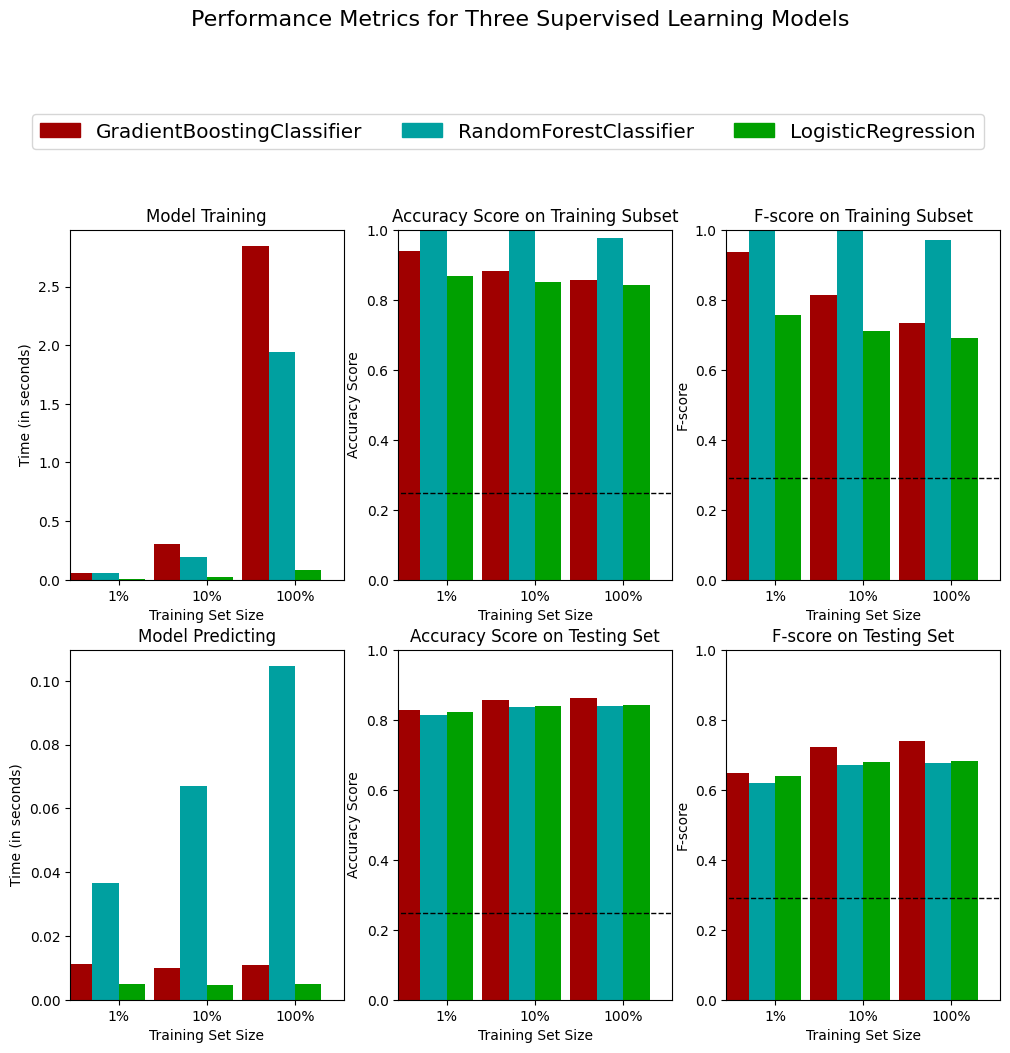

train_time  pred_time  acc_train  acc_test  \
model                      size                                               
GradientBoostingClassifier 1%        0.0585     0.0110     0.9400    0.8272   
                           10%       0.3017     0.0100     0.8833    0.8558   
                           100%      2.8432     0.0110     0.8567    0.8630   
RandomForestClassifier     1%        0.0540     0.0366     1.0000    0.8148   
                           10%       0.1921     0.0669     1.0000    0.8363   
                           100%      1.9441     0.1045     0.9767    0.8405   
LogisticRegression         1%        0.0080     0.0050     0.8667    0.8226   
                           10%       0.0225     0.0047     0.8500    0.8389   
                           100%      0.0789     0.0050     0.8433    0.8417   

                                 f_train  f_test  
model                      size                   
GradientBoostingClassifier 1%     0.9375  0.6492  
                           10%    0.8135  0.7214  
                           100%   0.7341  0.7395  
RandomForestClassifier     1%     1.0000  0.6191  
                           10%    1.0000  0.6697  
                           100%   0.9706  0.6769  
LogisticRegression         1%     0.7576  0.6390  
                           10%    0.7115  0.6783  
                           100%   0.6903  0.6826

In [10]:
# TODO: Import the three supervised learning models from sklearn
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# TODO: Initialize the three models
clf_A = GradientBoostingClassifier(random_state=0)
clf_B = RandomForestClassifier(random_state=0)
clf_C = LogisticRegression(random_state=0)

# TODO: Calculate the number of samples for 1%, 10%, and 100% of the training data
# HINT: samples_100 is the entire training set i.e. len(y_train)
# HINT: samples_10 is 10% of samples_100 (ensure to set the count of the values to be `int` and not `float`)
# HINT: samples_1 is 1% of samples_100 (ensure to set the count of the values to be `int` and not `float`)
samples_100 = len(y_train)
samples_10 = int(0.1 * samples_100)
samples_1 = int(0.01 * samples_100)

# Collect results on the learners
results = {}
for clf in [clf_A, clf_B, clf_C]:
    clf_name = clf.__class__.__name__
    results[clf_name] = {}
    for i, samples in enumerate([samples_1, samples_10, samples_100]):
        results[clf_name][i] = \
        train_predict(clf, samples, X_train, y_train, X_test, y_test)

# Run metrics visualization for the three supervised learning models chosen
vs.evaluate(results, accuracy, fscore)

# Small table of the same numbers (rows: model and training set size)
summary = pd.DataFrame([dict(model=name, size=size, **results[name][i])
                        for name in results
                        for i, size in enumerate(['1%', '10%', '100%'])]).set_index(['model', 'size'])
display(summary.round(4))

----
## Improving Results
In this final section, you will choose from the three supervised learning models the *best* model to use on the student data. You will then perform a grid search optimization for the model over the entire training set (`X_train` and `y_train`) by tuning at least one parameter to improve upon the untuned model's F-score. 

### Question 3 - Choosing the Best Model

* Based on the evaluation you performed earlier, in one to two paragraphs, explain to *CharityML* which of the three models you believe to be most appropriate for the task of identifying individuals that make more than \$50,000. 

**HINT:** 
Look at the graph at the bottom left from the cell above(the visualization created by `vs.evaluate(results, accuracy, fscore)`) and check the F score for the testing set when 100% of the training set is used. Which model has the highest score? Your answer should include discussion of the:
* metrics - F score on the testing when 100% of the training data is used, 
* prediction/training time
* the algorithm's suitability for the data.

**Answer:**

I recommend **Gradient Boosting** (`GradientBoostingClassifier`) for CharityML.

**Performance.** When trained on 100% of the training set, Gradient Boosting has the best scores on the testing set: an **F-score of 0.7395** and an accuracy of 0.8630. Logistic Regression reaches an F-score of 0.6826 (accuracy 0.8417) and Random Forest 0.6769 (accuracy 0.8405). All three are far above the naive predictor (F-score 0.2917), but Gradient Boosting leads by about 0.06 in F-score, which is the metric CharityML cares about because it rewards precision. Gradient Boosting also generalises well: its F-score on the training subset (0.73) is close to its test F-score (0.74). Random Forest scores 0.97 on the training subset but only 0.68 on the test set, so it is overfitting (memorising the training data).

**Training and prediction time.** Logistic Regression is the fastest (under 0.1 seconds to train on all 36,177 rows). Gradient Boosting takes about 3 seconds to train and about 0.01 seconds to predict, and Random Forest takes about 2 seconds to train but is about ten times slower than Gradient Boosting at predicting (about 0.1 seconds), because it has to run 100 deep trees. A few seconds of training is no problem for a charity that retrains the model rarely, and predicting is fast.

**Fit to the data.** The data has about 45,000 people, 103 features (most of them one-hot 0/1 columns) and imbalanced classes (24% earn more than \$50K). Tree-based boosting handles binary features without any extra work, finds combinations of features (for example married *and* well educated *and* with capital gains) that a linear model misses, and keeps correcting the cases it gets wrong, which helps with the smaller >50K class. For these reasons Gradient Boosting gives the best balance of accuracy and cost.

### Question 4 - Describing the Model in Layman's Terms

* In one to two paragraphs, explain to *CharityML*, in layman's terms, how the final model chosen is supposed to work. Be sure that you are describing the major qualities of the model, such as how the model is trained and how the model makes a prediction. Avoid using advanced mathematical jargon, such as describing equations.

**HINT:**

When explaining your model, if using external resources please include all citations.

**Answer:**

Our model, called *Gradient Boosting*, makes its decision with a long list of very simple yes/no questions, such as "Is this person married?" or "Does this person have more than 13 years of education?". One small set of such questions arranged like a flow chart is called a *decision tree*. **Training** works like a team of students learning from the mistakes of the students before them. The first tree looks at the census records of people whose income we already know and makes a rough guess for everyone. Then we check which people it guessed wrong. The second tree is built to fix those mistakes, the third tree fixes what is still wrong after the first two, and so on, a few hundred times. Each tree only gets a small vote (this is the "learning rate"), so no single tree can push the answer too far, and the team improves slowly and carefully instead of memorising the training data.

To **make a prediction** for a new person, we pass that person's information through all the trees. Each tree adds a small amount to a score that says "more likely above \$50K" or "more likely below \$50K". At the end the scores are added up: if the total points towards above \$50K, the model predicts that this person earns more than \$50,000 and CharityML can consider contacting them. Because many small, simple questions are combined, the model can notice combinations, for example that being married *and* well educated *and* having investment income together point strongly to a high income.

*Source for the method: J. H. Friedman, "Greedy Function Approximation: A Gradient Boosting Machine", Annals of Statistics, 2001, https://doi.org/10.1214/aos/1013203451; scikit-learn user guide, https://scikit-learn.org/stable/modules/ensemble.html*

### Implementation: Model Tuning
Fine tune the chosen model. Use grid search (`GridSearchCV`) with at least one important parameter tuned with at least 3 different values. You will need to use the entire training set for this. In the code cell below, you will need to implement the following:
- Import [`sklearn.grid_search.GridSearchCV`](http://scikit-learn.org/0.17/modules/generated/sklearn.grid_search.GridSearchCV.html) and [`sklearn.metrics.make_scorer`](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.make_scorer.html).
- Initialize the classifier you've chosen and store it in `clf`.
 - Set a `random_state` if one is available to the same state you set before.
- Create a dictionary of parameters you wish to tune for the chosen model.
 - Example: `parameters = {'parameter' : [list of values]}`.
 - **Note:** Avoid tuning the `max_features` parameter of your learner if that parameter is available!
- Use `make_scorer` to create an `fbeta_score` scoring object (with $\beta = 0.5$).
- Perform grid search on the classifier `clf` using the `'scorer'`, and store it in `grid_obj`.
- Fit the grid search object to the training data (`X_train`, `y_train`), and store it in `grid_fit`.

**Note:** Depending on the algorithm chosen and the parameter list, the following implementation may take some time to run!

In [11]:
# TODO: Import 'GridSearchCV', 'make_scorer', and any other necessary libraries
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer

# TODO: Initialize the classifier
clf = GradientBoostingClassifier(random_state=0)

# TODO: Create the parameters list you wish to tune, using a dictionary if needed.
# HINT: parameters = {'parameter_1': [value1, value2], 'parameter_2': [value1, value2]}
parameters = {'n_estimators': [100, 200, 400],
              'learning_rate': [0.05, 0.1, 0.5]}

# TODO: Make an fbeta_score scoring object using make_scorer()
scorer = make_scorer(fbeta_score, beta=0.5)

# TODO: Perform grid search on the classifier using 'scorer' as the scoring method using GridSearchCV()
grid_obj = GridSearchCV(clf, parameters, scoring=scorer, cv=5, n_jobs=-1)

# TODO: Fit the grid search object to the training data and find the optimal parameters using fit()
grid_fit = grid_obj.fit(X_train, y_train)

# Get the estimator
best_clf = grid_fit.best_estimator_
print("Best parameters:", grid_fit.best_params_)
print("Best cross-validated F-score: {:.4f}\n".format(grid_fit.best_score_))

# Make predictions using the unoptimized and model
predictions = (clf.fit(X_train, y_train)).predict(X_test)
best_predictions = best_clf.predict(X_test)

# Report the before-and-afterscores
print("Unoptimized model\n------")
print("Accuracy score on testing data: {:.4f}".format(accuracy_score(y_test, predictions)))
print("F-score on testing data: {:.4f}".format(fbeta_score(y_test, predictions, beta = 0.5)))
print("\nOptimized Model\n------")
print("Final accuracy score on the testing data: {:.4f}".format(accuracy_score(y_test, best_predictions)))
print("Final F-score on the testing data: {:.4f}".format(fbeta_score(y_test, best_predictions, beta = 0.5)))

Best parameters: {'learning_rate': 0.1, 'n_estimators': 400}
Best cross-validated F-score: 0.7555



Unoptimized model
------
Accuracy score on testing data: 0.8630
F-score on testing data: 0.7395

Optimized Model
------
Final accuracy score on the testing data: 0.8708
Final F-score on the testing data: 0.7531


### Question 5 - Final Model Evaluation

* What is your optimized model's accuracy and F-score on the testing data? 
* Are these scores better or worse than the unoptimized model? 
* How do the results from your optimized model compare to the naive predictor benchmarks you found earlier in **Question 1**?_  

**Note:** Fill in the table below with your results, and then provide discussion in the **Answer** box.

#### Results:

|     Metric     | Unoptimized Model | Optimized Model |
| :------------: | :---------------: | :-------------: |
| Accuracy Score |      0.8630       |     0.8708      |
| F-score        |      0.7395       |     0.7531      |

*Optimized model: `GradientBoostingClassifier(random_state=0, learning_rate=0.1, n_estimators=400)`, found with `GridSearchCV` (5-fold cross-validation, F0.5 scorer).*

**Answer:**

- The optimized model has an **accuracy of 0.8708** and an **F-score of 0.7531** on the testing data.
- These scores are **better than the unoptimized model** (accuracy 0.8630, F-score 0.7395): +0.0078 in accuracy and +0.0136 in F-score. Grid search kept the default learning rate (0.1) but chose 400 trees instead of 100, so the model had more steps to correct its mistakes. A learning rate of 0.5 was worse because the model then learns too fast and overfits.
- Compared with the **naive predictor** from Question 1 (accuracy 0.2478, F-score 0.2917), the optimized model is much better: accuracy is about 3.5 times higher and the F-score is about 2.6 times higher. The naive predictor labels everyone as a likely donor, so three out of four people it picks are wrong; our model is correct for about 87% of people and is much more precise about who earns more than \$50,000.

----
## Feature Importance

An important task when performing supervised learning on a dataset like the census data we study here is determining which features provide the most predictive power. By focusing on the relationship between only a few crucial features and the target label we simplify our understanding of the phenomenon, which is most always a useful thing to do. In the case of this project, that means we wish to identify a small number of features that most strongly predict whether an individual makes at most or more than \$50,000.

Choose a scikit-learn classifier (e.g., adaboost, random forests) that has a `feature_importance_` attribute, which is a function that ranks the importance of features according to the chosen classifier.  In the next python cell fit this classifier to training set and use this attribute to determine the top 5 most important features for the census dataset.

### Question 6 - Feature Relevance Observation
When **Exploring the Data**, it was shown there are thirteen available features for each individual on record in the census data. Of these thirteen records, which five features do you believe to be most important for prediction, and in what order would you rank them and why?

**Answer:**

My ranking, written before looking at the feature importances (most important first):

1. **education-num** - More years of education usually lead to better-paid, professional jobs. It is a number, so it also shows *how much* education a person has.
2. **occupation** - Some jobs pay much more than others (for example Exec-managerial or Prof-specialty compared with Handlers-cleaners or Other-service).
3. **age** - Income usually grows with work experience. Very young people (students, first jobs) rarely earn more than \$50K.
4. **capital-gain** - Having capital gains means a person owns investments such as shares or property, which is a sign of wealth and higher income.
5. **hours-per-week** - People who work full time or overtime earn more than people who work part time.

### Implementation - Extracting Feature Importance
Choose a `scikit-learn` supervised learning algorithm that has a `feature_importance_` attribute availble for it. This attribute is a function that ranks the importance of each feature when making predictions based on the chosen algorithm.

In the code cell below, you will need to implement the following:
 - Import a supervised learning model from sklearn if it is different from the three used earlier.
 - Train the supervised model on the entire training set.
 - Extract the feature importances using `'.feature_importances_'`.

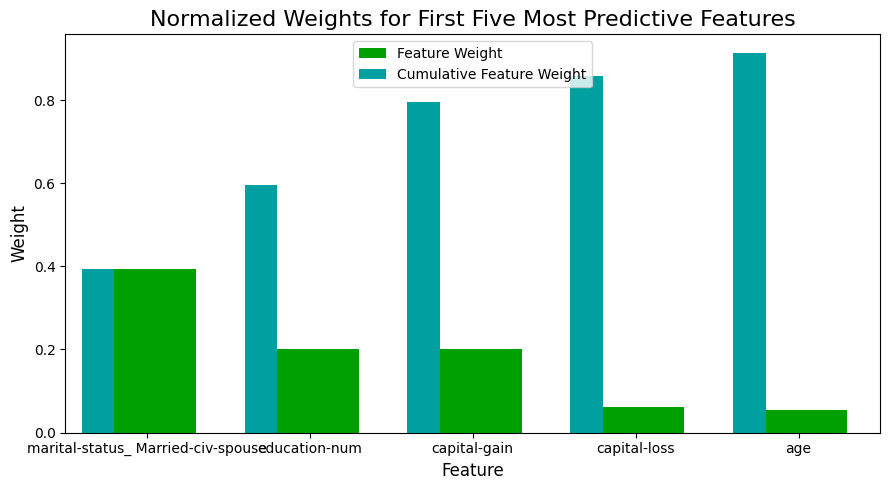

,importance
marital-status_ Married-civ-spouse,0.3940
education-num,0.2018
capital-gain,0.2001
capital-loss,0.0627
age,0.0543
hours-per-week,0.0297
occupation_ Exec-managerial,0.0166
occupation_ Prof-specialty,0.0079
occupation_ Other-service,0.0059
occupation_ Farming-fishing,0.0051


In [12]:
# TODO: Import a supervised learning model that has 'feature_importances_'
# GradientBoostingClassifier was already imported above and has 'feature_importances_'

# TODO: Train the supervised model on the training set using .fit(X_train, y_train)
model = GradientBoostingClassifier(random_state=0).fit(X_train, y_train)

# TODO: Extract the feature importances using .feature_importances_
importances = model.feature_importances_

# Plot
vs.feature_plot(importances, X_train, y_train)

# Print the ten largest importances with their names
top10 = pd.Series(importances, index=X_train.columns).sort_values(ascending=False).head(10)
display(top10.round(4).to_frame('importance'))

### Question 7 - Extracting Feature Importance

Observe the visualization created above which displays the five most relevant features for predicting if an individual makes at most or above \$50,000.  
* How do these five features compare to the five features you discussed in **Question 6**?
* If you were close to the same answer, how does this visualization confirm your thoughts? 
* If you were not close, why do you think these features are more relevant?

**Answer:**

The model's top five features (with their importance) are:

1. `marital-status_ Married-civ-spouse` (0.394)
2. `education-num` (0.202)
3. `capital-gain` (0.200)
4. `capital-loss` (0.063)
5. `age` (0.054)

Together they hold about 91% of the total importance.

**What matched:** Three of my five features are in the top five: **education-num**, **capital-gain** and **age**. This confirms my ideas that education level, investment income and work experience are strong signs of a high income. Education-num and capital-gain are almost equally important for the model.

**What did not match:**

- **Marital status** is the single most important feature, and I did not rank it at all. In this 1994 census data, married people (most of them husbands, see the `relationship` feature) earn more than \$50K much more often than single people. Being married also carries information about age, life stage and job stability at the same time, so one yes/no question separates a large group of people very well.
- **capital-loss** is in the top five, but I did not choose it. A person can only report a capital loss if they own investments, so, like capital-gain, it is a sign of wealth.
- **occupation** is not in the top five. After one-hot encoding it is split into 14 separate 0/1 columns, so its importance is shared between them (the largest, `occupation_ Exec-managerial`, has only 0.017). Part of its information is also already in education-num.
- **hours-per-week** is close: it is number 6 (0.030).

So my intuition was partly right, but the model shows that family situation and investment income (gains *and* losses) matter more than I expected.

### Feature Selection
How does a model perform if we only use a subset of all the available features in the data? With less features required to train, the expectation is that training and prediction time is much lower — at the cost of performance metrics. From the visualization above, we see that the top five most important features contribute more than half of the importance of **all** features present in the data. This hints that we can attempt to *reduce the feature space* and simplify the information required for the model to learn. The code cell below will use the same optimized model you found earlier, and train it on the same training set *with only the top five important features*. 

In [13]:
# Import functionality for cloning a model
from sklearn.base import clone

# Reduce the feature space
X_train_reduced = X_train[X_train.columns.values[(np.argsort(importances)[::-1])[:5]]]
X_test_reduced = X_test[X_test.columns.values[(np.argsort(importances)[::-1])[:5]]]

# Train on the "best" model found from grid search earlier
start = time()
clf = (clone(best_clf)).fit(X_train_reduced, y_train)
reduced_train_time = time() - start

# For comparison, time the same model on all features
start = time()
clone(best_clf).fit(X_train, y_train)
full_train_time = time() - start

# Make new predictions
reduced_predictions = clf.predict(X_test_reduced)

# Report scores from the final model using both versions of data
print("Final Model trained on full data\n------")
print("Accuracy on testing data: {:.4f}".format(accuracy_score(y_test, best_predictions)))
print("F-score on testing data: {:.4f}".format(fbeta_score(y_test, best_predictions, beta = 0.5)))
print("\nFinal Model trained on reduced data\n------")
print("Accuracy on testing data: {:.4f}".format(accuracy_score(y_test, reduced_predictions)))
print("F-score on testing data: {:.4f}".format(fbeta_score(y_test, reduced_predictions, beta = 0.5)))
print("\nTraining time: all features {:.2f}s, top 5 features {:.2f}s".format(full_train_time, reduced_train_time))

Final Model trained on full data
------
Accuracy on testing data: 0.8708
F-score on testing data: 0.7531

Final Model trained on reduced data
------
Accuracy on testing data: 0.8588
F-score on testing data: 0.7249

Training time: all features 11.36s, top 5 features 2.44s


### Question 8 - Effects of Feature Selection

* How does the final model's F-score and accuracy score on the reduced data using only five features compare to those same scores when all features are used?
* If training time was a factor, would you consider using the reduced data as your training set?

**Answer:**

- With only the top five features, the final model reaches an **accuracy of 0.8588** and an **F-score of 0.7249**. With all 103 features it reaches 0.8708 and 0.7531. So the reduced model loses about 0.012 in accuracy and about 0.028 in F-score (about 4% of the F-score). It is still much better than the naive predictor and close to the unoptimized model trained on all features (F-score 0.7395).
- Training was about 4-5 times faster with the five features (about 2.5 seconds instead of about 11.6 seconds in the run above). **If training time was an important factor** (for example with much more data or frequent retraining), I **would consider the reduced data**, because the small loss in F-score is a fair price for a much faster and simpler model. For CharityML today, training on all features only takes a few seconds, so I would keep the full model and its higher precision.

> **Note**: Once you have completed all of the code implementations and successfully answered each question above, you may finalize your work by exporting the iPython Notebook as an HTML document. You can do this by using the menu above and navigating to  
**File -> Download as -> HTML (.html)**. Include the finished document along with this notebook as your submission.